In [1]:
# Cell 1: Set paths and processing parameters.
from pathlib import Path
import sys

# Run from training/ or its parent project directory.
TRAINING_DIR = Path.cwd().resolve()
if not (TRAINING_DIR / "superpixel_RF_GMM_training_refactored.ipynb").is_file():
    TRAINING_DIR = TRAINING_DIR / "training"
if not (TRAINING_DIR / "superpixel_RF_GMM_training_refactored.ipynb").is_file():
    raise FileNotFoundError("Start Jupyter from training/ or its parent directory.")
PROJECT_ROOT = TRAINING_DIR.parent
sys.path.insert(0, str(PROJECT_ROOT / "implement"))  # Reuse matching implementation functions.
sys.path.insert(0, str(TRAINING_DIR))
RUN_DIR = TRAINING_DIR / "output" / "full_archived_labels_001"  # Use a new name for a full-data run.
COLOR_REFERENCE_PATH = PROJECT_ROOT / "implement" / "data" / "models" / "rf_step1.pkl"
CONFIG = {
    "data_dir": "data/mag500/training",
    "max_images": None,  # All 166 images matching the archived human-label table.
    "crop": {"top": 60, "bottom": 100, "left": 60, "right": 100},
    "n_segments": 300, "compactness": 10.0,
}
DATA_DIR = PROJECT_ROOT / CONFIG["data_dir"]
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Training image directory not found: {DATA_DIR}")
print(f"Project: {PROJECT_ROOT}\nTraining images: {DATA_DIR}\nRun: {RUN_DIR}")
print(f"Available JPG images: {sum(1 for p in DATA_DIR.glob('*.jpg') if p.is_file())}")

Project: /home/kmanabe2403/dune
Training images: /home/kmanabe2403/dune/data/mag500/training
Run: /home/kmanabe2403/dune/training/output/full_archived_labels_001
Available JPG images: 166


In [2]:
# Cell 2: Save naturally sorted training image paths and settings.
# Rerunning overwrites metadata. Use a new run name when changing inputs or settings.
from training_pipeline import prepare_training_run

prepare_training_run(PROJECT_ROOT, RUN_DIR, CONFIG)

Selected images: 166 | Metadata: /home/kmanabe2403/dune/training/output/full_archived_labels_001/metadata


In [3]:
# Cell 3: Crop images, compute SLIC segments, and save per-image Lab means.
# Process only the images selected in Cell 2 (all images by default).
from crystal_preprocessing import run_preprocessing

run_preprocessing(PROJECT_ROOT, RUN_DIR)

Verified full 166-image preparation already completed: 3


In [4]:
# Cell 4: Save pixel-Lab corrections using the fixed reference from the existing RF model.
# Reuse the implementation function; do not recalculate the reference from these images.
from crystal_preprocessing import run_color_correction

run_color_correction(RUN_DIR, COLOR_REFERENCE_PATH)

Verified full 166-image preparation already completed: 4


In [5]:
# Cell 5: Calculate and save the same 18 features used by implementation.
# Use archived-training rgb2gray and pixel Lab correction before averaging.
from crystal_features import run_feature_extraction

run_feature_extraction(RUN_DIR)

Verified full 166-image preparation already completed: 5


In [6]:
# Cell 6: Fit and save per-image GMM results using the original training settings.
# Component counts are keyed by image name, so a preview uses the same settings.
from training_pipeline import run_training_gmm

GMM_SETTINGS_PATH = TRAINING_DIR / "data" / "tables" / "gmm_settings.csv"
run_training_gmm(RUN_DIR, GMM_SETTINGS_PATH, pca_components=2, probability_cut=0.90)

[1/166] 0000_20260807_095058: 2 clusters, 170 high confidence
[2/166] 0002_20260807_095234: 2 clusters, 87 high confidence
[3/166] 0003_20260807_095334: 2 clusters, 53 high confidence
[4/166] 0006_20260807_095518: 2 clusters, 175 high confidence
[5/166] 0020_20260806_140100: 3 clusters, 238 high confidence
[6/166] 0022_20260806_140217: 2 clusters, 151 high confidence
[7/166] 0023_20260806_140255: 2 clusters, 126 high confidence
[8/166] 0033_20260806_151056: 2 clusters, 154 high confidence
[9/166] 0034_20260806_151135: 3 clusters, 58 high confidence
[10/166] 0037_20260806_151408: 3 clusters, 86 high confidence
[11/166] 0053_20260807_103050: 3 clusters, 190 high confidence
[12/166] 0068_20260807_124941: 2 clusters, 272 high confidence
[13/166] 0074_20260807_124023: 3 clusters, 134 high confidence
[14/166] 0075_20260807_124101: 3 clusters, 136 high confidence
[15/166] 0078_20260807_124259: 3 clusters, 113 high confidence
[16/166] 0079_20260807_124334: 3 clusters, 111 high confidence
[17/1

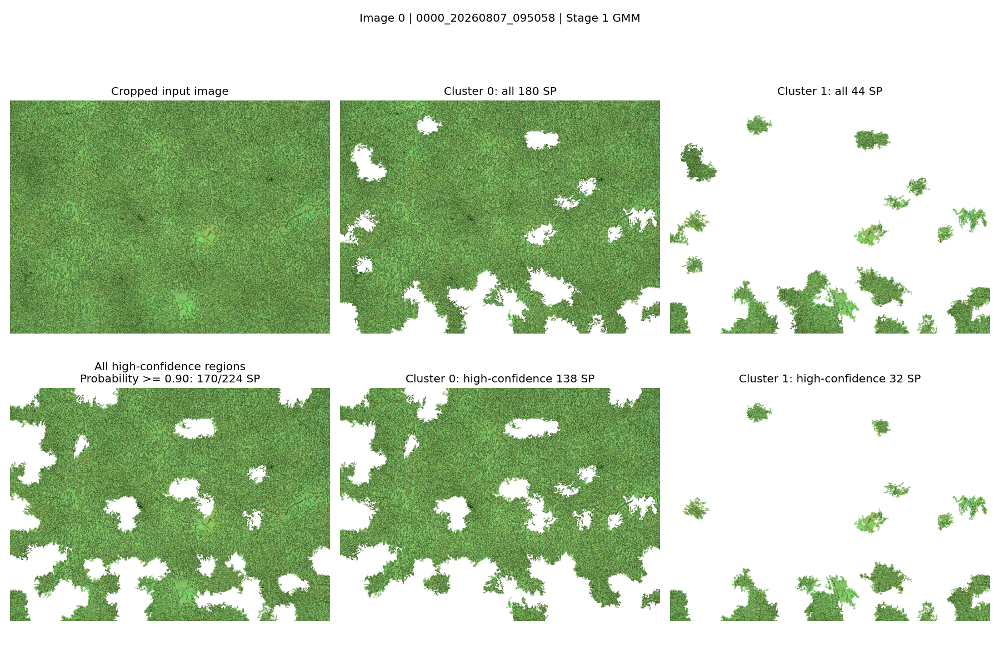

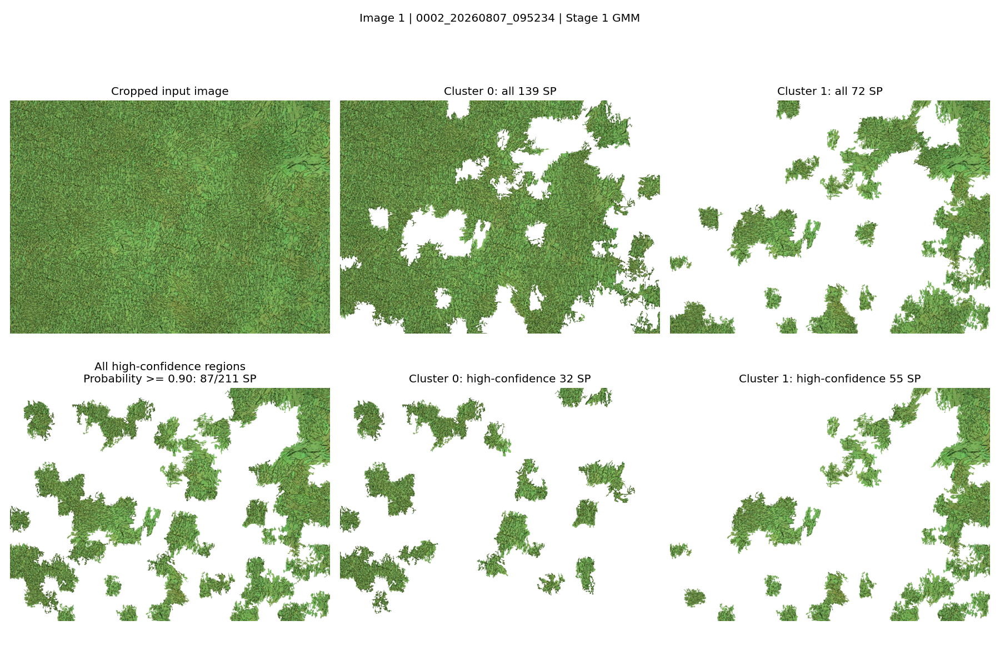

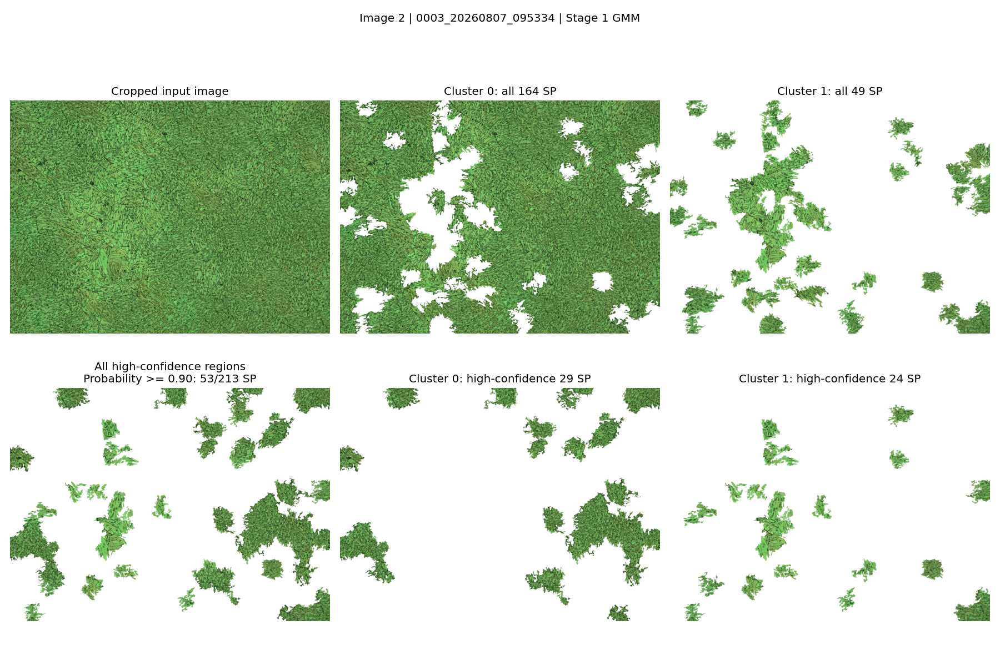

Saved: /home/kmanabe2403/dune/training/output/full_archived_labels_001/gmm/stage1/figures/image_0000.png
Saved: /home/kmanabe2403/dune/training/output/full_archived_labels_001/gmm/stage1/figures/image_0001.png
Saved: /home/kmanabe2403/dune/training/output/full_archived_labels_001/gmm/stage1/figures/image_0002.png
PDF: /home/kmanabe2403/dune/training/output/full_archived_labels_001/gmm/stage1/figures/review.pdf


In [7]:
# Cell 7: Review saved stage-1 GMM clusters and high-confidence regions.
# Change image_ids to inspect other selected images; GMM is not recalculated.
from training_review import show_training_gmm

show_training_gmm(RUN_DIR, image_ids=[0, 1, 2])

In [8]:
# Cell 8: Split selected stage-1 clusters using the shared GMM calculation.
# Use human-label-aligned archive targets; see manual_labels_source.json for image 5.
# IDs are zero-based; no stage-1 probability cut is applied.
from training_pipeline import run_training_gmm_stage2

GMM_STAGE2_SETTINGS_PATH = TRAINING_DIR / "data" / "tables" / "manual_labels_stage2_settings.csv"
run_training_gmm_stage2(RUN_DIR, GMM_STAGE2_SETTINGS_PATH, pca_components=2, probability_cut=0.90)

image_0003, parent cluster 0: 154 SP -> 2 clusters
image_0013, parent cluster 2: 135 SP -> 2 clusters
image_0030, parent cluster 0: 147 SP -> 2 clusters
image_0039, parent cluster 0: 31 SP -> 2 clusters
image_0039, parent cluster 1: 209 SP -> 2 clusters
image_0084, parent cluster 0: 120 SP -> 2 clusters
image_0085, parent cluster 0: 156 SP -> 2 clusters
image_0088, parent cluster 1: 168 SP -> 2 clusters
image_0092, parent cluster 0: 95 SP -> 2 clusters
image_0092, parent cluster 2: 114 SP -> 2 clusters
image_0093, parent cluster 1: 87 SP -> 2 clusters
image_0093, parent cluster 2: 106 SP -> 2 clusters
image_0109, parent cluster 0: 99 SP -> 2 clusters
image_0111, parent cluster 0: 71 SP -> 2 clusters
image_0123, parent cluster 0: 123 SP -> 2 clusters
image_0123, parent cluster 1: 74 SP -> 2 clusters
image_0132, parent cluster 0: 82 SP -> 2 clusters
image_0133, parent cluster 0: 94 SP -> 2 clusters
image_0133, parent cluster 2: 90 SP -> 2 clusters
image_0134, parent cluster 1: 70 SP -> 2

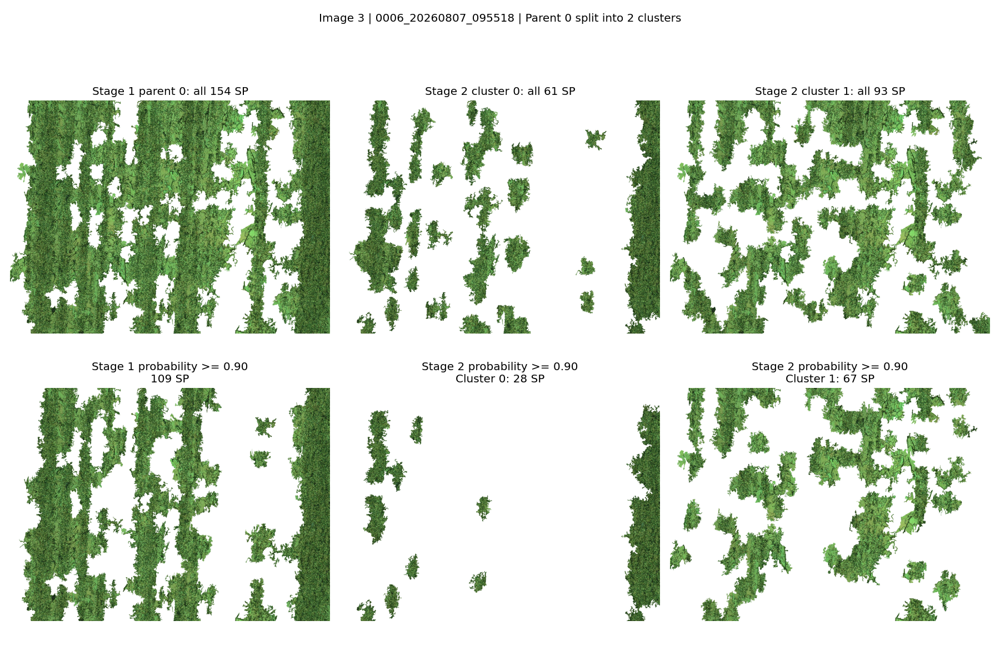

Saved: /home/kmanabe2403/dune/training/output/full_archived_labels_001/gmm/stage2/figures/image_0003_cluster_0000.png
PDF: /home/kmanabe2403/dune/training/output/full_archived_labels_001/gmm/stage2/figures/review.pdf


In [9]:
# Cell 9: Compare saved stage-1 parent clusters with their stage-2 splits.
# Each lower panel uses its own stage's probability threshold.
from training_review import show_training_gmm_stage2

show_training_gmm_stage2(RUN_DIR, image_ids=[3])

In [10]:
# Cell 10: Create final GMM groups and import archived human labels.
# Match image names and cluster IDs; conflicting human edits are never overwritten.
from training_labels import prepare_training_labels, import_training_labels

TRAINING_LABELS_PATH = prepare_training_labels(RUN_DIR)
# Human labels extracted from the archive; no RF-generated ground truth.
TRAINING_LABELS_PATH = import_training_labels(RUN_DIR, TRAINING_DIR / "data/tables/manual_labels.csv")


Existing manual labels kept: /home/kmanabe2403/dune/training/output/full_archived_labels_001/labels/cluster_labels.csv
Imported 310 archived human labels by image and cluster: /home/kmanabe2403/dune/training/output/full_archived_labels_001/labels/cluster_labels.csv


In [11]:
# Cell 11: Assign human labels to superpixels and save the feature table.
# Keep archived parent/superpixel row order for reproducible RF bootstrap samples.
# Blank labels are preserved; stage2_cluster=-1 means no second-stage split.
from training_dataset import build_training_dataset

TRAINING_DATASET_PATH = build_training_dataset(RUN_DIR)

Saved 41216 superpixels from 166 images: /home/kmanabe2403/dune/training/output/full_archived_labels_001/datasets/superpixels.csv


In [12]:
# Cell 12: Review label counts and filtering before RF training.
# Label 0 remains in the source table but is excluded from training, as in the original.
from training_dataset import inspect_training_dataset

GMM_PROBABILITY_CUT = 0.70
EXCLUDED_LABELS = [0]
inspect_training_dataset(TRAINING_DATASET_PATH, GMM_PROBABILITY_CUT, EXCLUDED_LABELS)

         status  n_superpixels
       eligible          37602
 excluded_label            562
low_probability           3052
Images: 166 | Probability cut: 0.7 | Excluded labels: [0]


In [13]:
# Cell 13: Map manual labels to the original five stage-1 RF groups.
# RF labels are 0-4 in this order. Edit these groups to change the classification task.
from training_dataset import group_training_labels

RF_GROUPS = {
    "1": [11, 12, 13, 14], "2": [21, 22, 23], "3": [31, 32, 33],
    "4": [41, 42, 43, 44], "5": [51],
}
RF_TRAINING_PATH = group_training_labels(TRAINING_DATASET_PATH, RF_GROUPS, GMM_PROBABILITY_CUT, EXCLUDED_LABELS)

RF 0 (1): 4539 superpixels
RF 1 (2): 5642 superpixels
RF 2 (3): 7018 superpixels
RF 3 (4): 20313 superpixels
RF 4 (5): 24 superpixels
Unmapped eligible rows: 66 | Saved: /home/kmanabe2403/dune/training/output/full_archived_labels_001/datasets/stage1_training.csv


In [14]:
# Cell 14: Evaluate RF on separate image groups, then fit the exported model on all eligible data.
# Identical source files stay in the same partition. Missing labels stop training safely.
from training_rf import train_stage1_rf

train_stage1_rf(PROJECT_ROOT, RUN_DIR, RF_TRAINING_PATH, test_size=0.25, n_estimators=300, random_state=0)

Held-out accuracy: 0.7663 | Macro F1: 0.6512
Model refitted on 37536 eligible superpixels. Saved: /home/kmanabe2403/dune/training/output/full_archived_labels_001/models/stage1


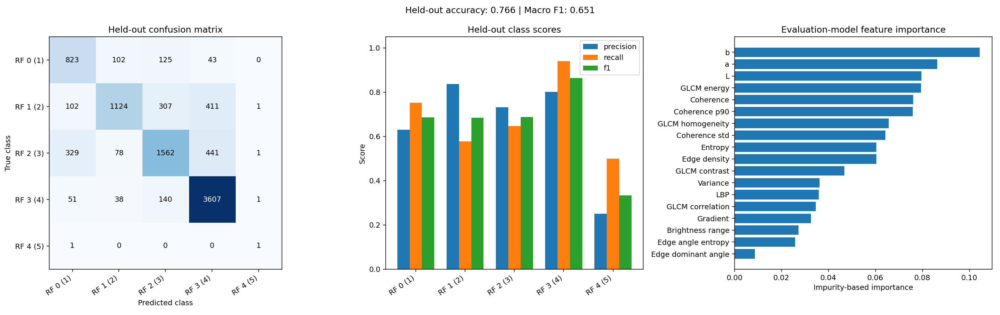

 rf_label     name  precision   recall       f1  support
        0 RF 0 (1)   0.630168 0.752973 0.686119     1093
        1 RF 1 (2)   0.837556 0.577892 0.683906     1945
        2 RF 2 (3)   0.731959 0.647864 0.687349     2411
        3 RF 3 (4)   0.801199 0.940057 0.865092     3837
        4 RF 4 (5)   0.250000 0.500000 0.333333        2
Saved: /home/kmanabe2403/dune/training/output/full_archived_labels_001/models/stage1/evaluation


In [15]:
# Cell 15: Review held-out confusion, class scores, and feature importance.
# Saved evaluation outputs are used; no RF training is repeated.
from training_evaluation import show_rf_evaluation

show_rf_evaluation(RUN_DIR, top_features=18)

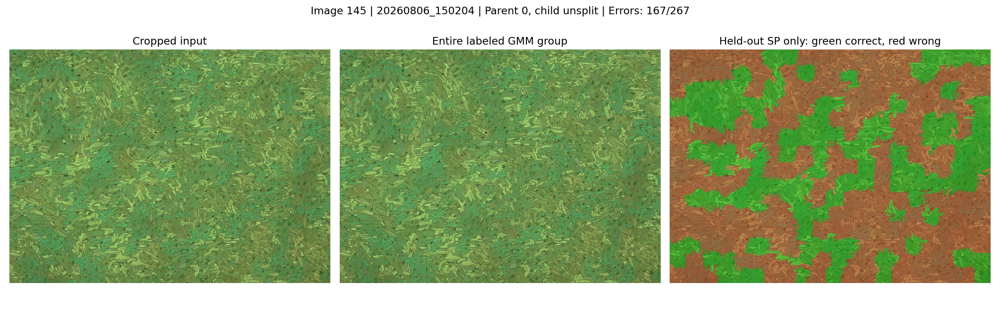

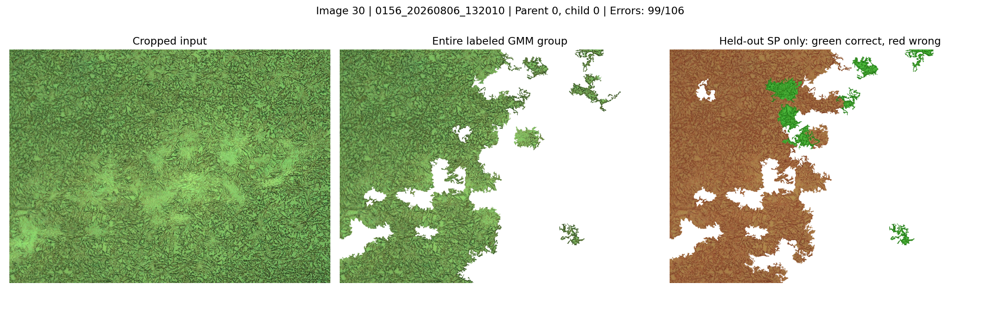

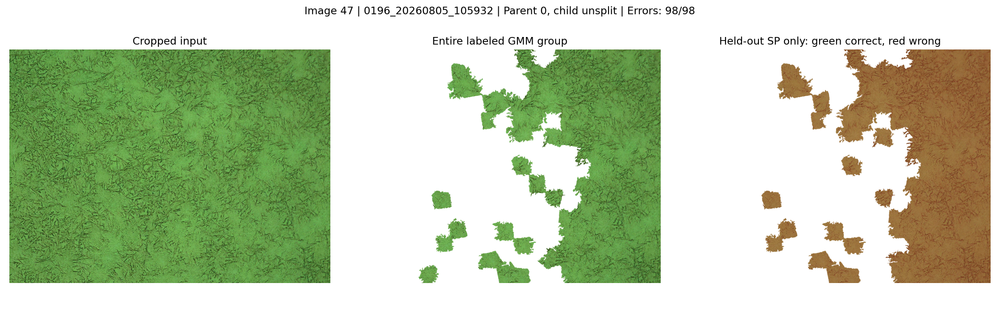

Saved 3 error-group figures: /home/kmanabe2403/dune/training/output/full_archived_labels_001/models/stage1/evaluation/misclassifications


In [16]:
# Cell 16: Inspect the GMM groups with the most held-out classification errors.
# The colored panel shows evaluated SPs only: green is correct and red is incorrect.
from training_evaluation import show_rf_errors

show_rf_errors(RUN_DIR, max_groups=3)

In [17]:
# Cell 17: Prepare parent-specific stage-2 RF datasets using manual labels.
# Keys are the zero-based parent paths used by implementation; child order sets RF class IDs.
from training_hierarchy import prepare_hierarchy_stage

STAGE2_GROUPS = {
    "1": {"21": [21], "22": [22], "23": [23]},
    "2": {"31+32": [31, 32], "33": [33]},
    "3": {"41+44": [41, 44], "42": [42], "43": [43]},
}
prepare_hierarchy_stage(RUN_DIR, stage=2, groups=STAGE2_GROUPS)

Stage 2, parent 1: 5642 eligible superpixels
Stage 2, parent 2: 7018 eligible superpixels
Stage 2, parent 3: 20313 eligible superpixels
Saved: /home/kmanabe2403/dune/training/output/full_archived_labels_001/datasets/stage2


In [18]:
# Cell 18: Train stage-2 RF models with the same image split as stage 1.
# Missing labels/classes produce a not_trained status for the affected parent.
from training_hierarchy import train_hierarchy_stage

train_hierarchy_stage(PROJECT_ROOT, RUN_DIR, stage=2, n_estimators=300, random_state=0)

Training stage 2, parent 1
Held-out accuracy: 0.7753 | Macro F1: 0.7666
Model refitted on 5642 eligible superpixels. Saved: /home/kmanabe2403/dune/training/output/full_archived_labels_001/models/stage2/parent_1
Training stage 2, parent 2
Held-out accuracy: 0.6321 | Macro F1: 0.6311
Model refitted on 7018 eligible superpixels. Saved: /home/kmanabe2403/dune/training/output/full_archived_labels_001/models/stage2/parent_2
Training stage 2, parent 3
Held-out accuracy: 0.7420 | Macro F1: 0.5988
Model refitted on 20313 eligible superpixels. Saved: /home/kmanabe2403/dune/training/output/full_archived_labels_001/models/stage2/parent_3


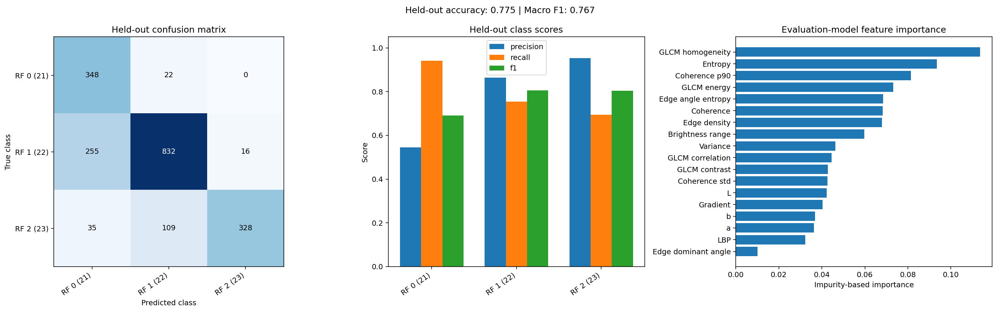

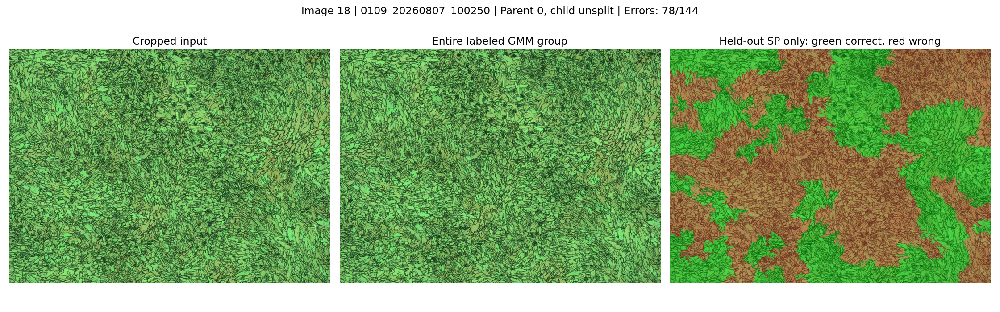

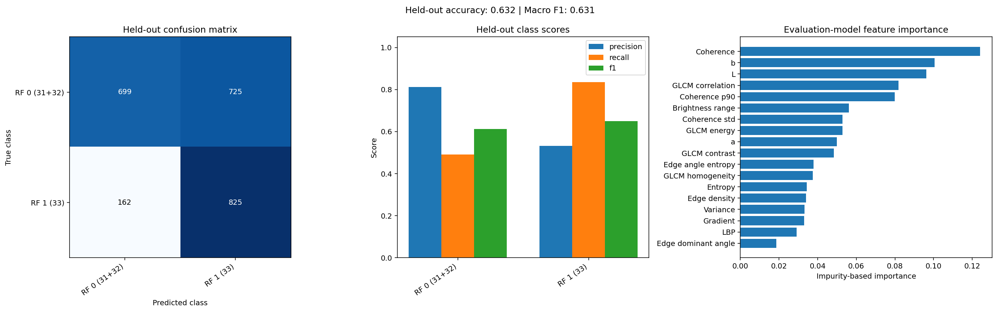

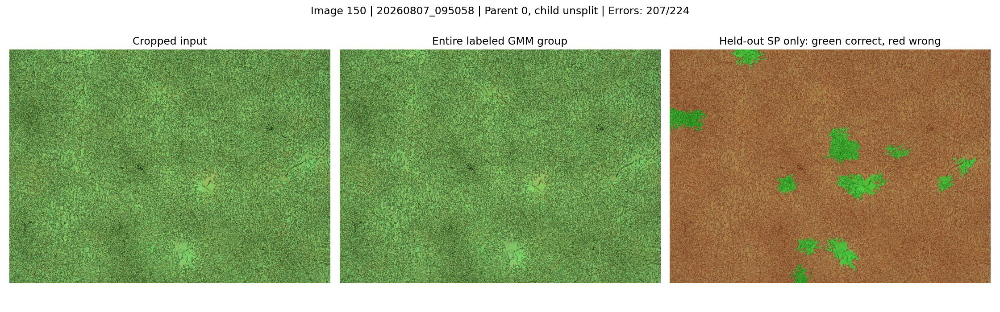

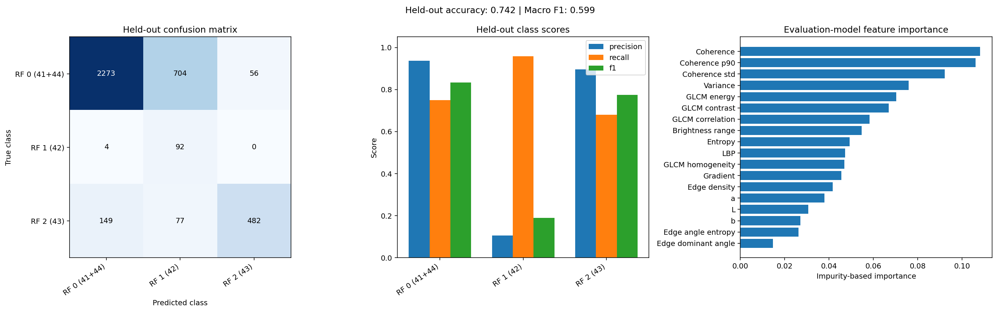

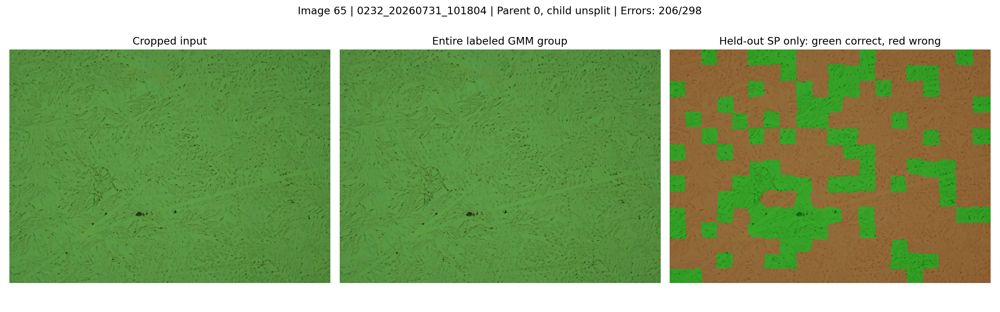

Stage 2, parent 1
 rf_label      name  precision   recall       f1  support
        0 RF 0 (21)   0.545455 0.940541 0.690476      370
        1 RF 1 (22)   0.863967 0.754306 0.805421     1103
        2 RF 2 (23)   0.953488 0.694915 0.803922      472
Saved: /home/kmanabe2403/dune/training/output/full_archived_labels_001/models/stage2/parent_1/evaluation
Saved 1 error-group figures: /home/kmanabe2403/dune/training/output/full_archived_labels_001/models/stage2/parent_1/evaluation/misclassifications
Stage 2, parent 2
 rf_label         name  precision   recall       f1  support
        0 RF 0 (31+32)   0.811847 0.490871 0.611816     1424
        1    RF 1 (33)   0.532258 0.835866 0.650374      987
Saved: /home/kmanabe2403/dune/training/output/full_archived_labels_001/models/stage2/parent_2/evaluation
Saved 1 error-group figures: /home/kmanabe2403/dune/training/output/full_archived_labels_001/models/stage2/parent_2/evaluation/misclassifications
Stage 2, parent 3
 rf_label         name  preci

In [19]:
# Cell 19: Review stage-2 held-out scores and a small number of error groups.
from training_hierarchy import show_hierarchy_stage

show_hierarchy_stage(RUN_DIR, stage=2, max_error_groups=1)

In [20]:
# Cell 20: Prepare stage-3 data for parent 20 (manual labels 31 versus 32).
# Path 20 means stage-1 class 2 followed by stage-2 class 0.
STAGE3_GROUPS = {"20": {"31": [31], "32": [32]}}
prepare_hierarchy_stage(RUN_DIR, stage=3, groups=STAGE3_GROUPS)

Stage 3, parent 20: 3063 eligible superpixels
Saved: /home/kmanabe2403/dune/training/output/full_archived_labels_001/datasets/stage3


In [21]:
# Cell 21: Train stage-3 RF using the fixed stage-1 image split.
train_hierarchy_stage(PROJECT_ROOT, RUN_DIR, stage=3, n_estimators=300, random_state=0)

Training stage 3, parent 20
Held-out accuracy: 0.8371 | Macro F1: 0.8092
Model refitted on 3063 eligible superpixels. Saved: /home/kmanabe2403/dune/training/output/full_archived_labels_001/models/stage3/parent_20


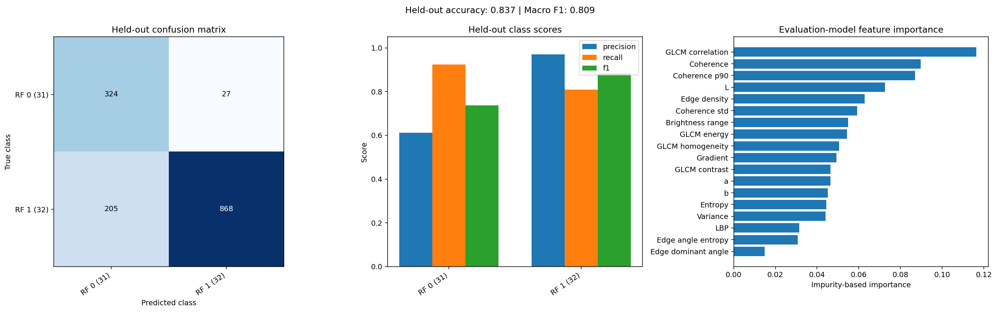

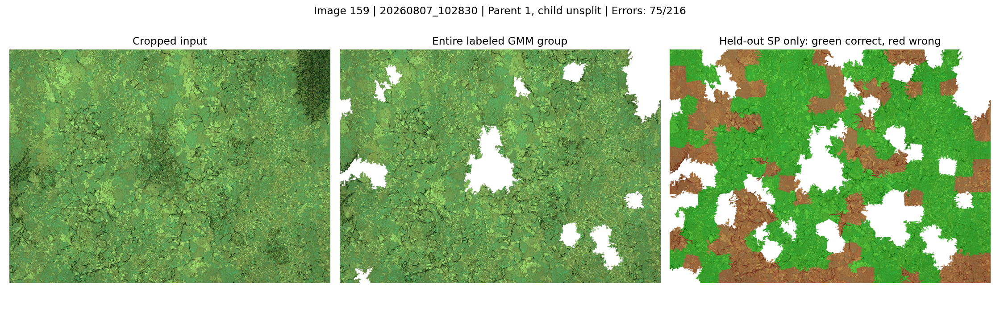

Stage 3, parent 20
 rf_label      name  precision   recall       f1  support
        0 RF 0 (31)   0.612476 0.923077 0.736364      351
        1 RF 1 (32)   0.969832 0.808947 0.882114     1073
Saved: /home/kmanabe2403/dune/training/output/full_archived_labels_001/models/stage3/parent_20/evaluation
Saved 1 error-group figures: /home/kmanabe2403/dune/training/output/full_archived_labels_001/models/stage3/parent_20/evaluation/misclassifications


In [22]:
# Cell 22: Review stage-3 held-out scores and misclassified regions.
show_hierarchy_stage(RUN_DIR, stage=3, max_error_groups=1)

In [23]:
# Cell 23: Export a separate implementation bundle of final all-data models.
# Feature order, class coverage, crop/SLIC settings, and color references must match.
from training_bundle import export_implement_bundle

export_implement_bundle(RUN_DIR)

Exported 5 compatible RF models and a color reference: /home/kmanabe2403/dune/training/output/full_archived_labels_001/export/implement_bundle


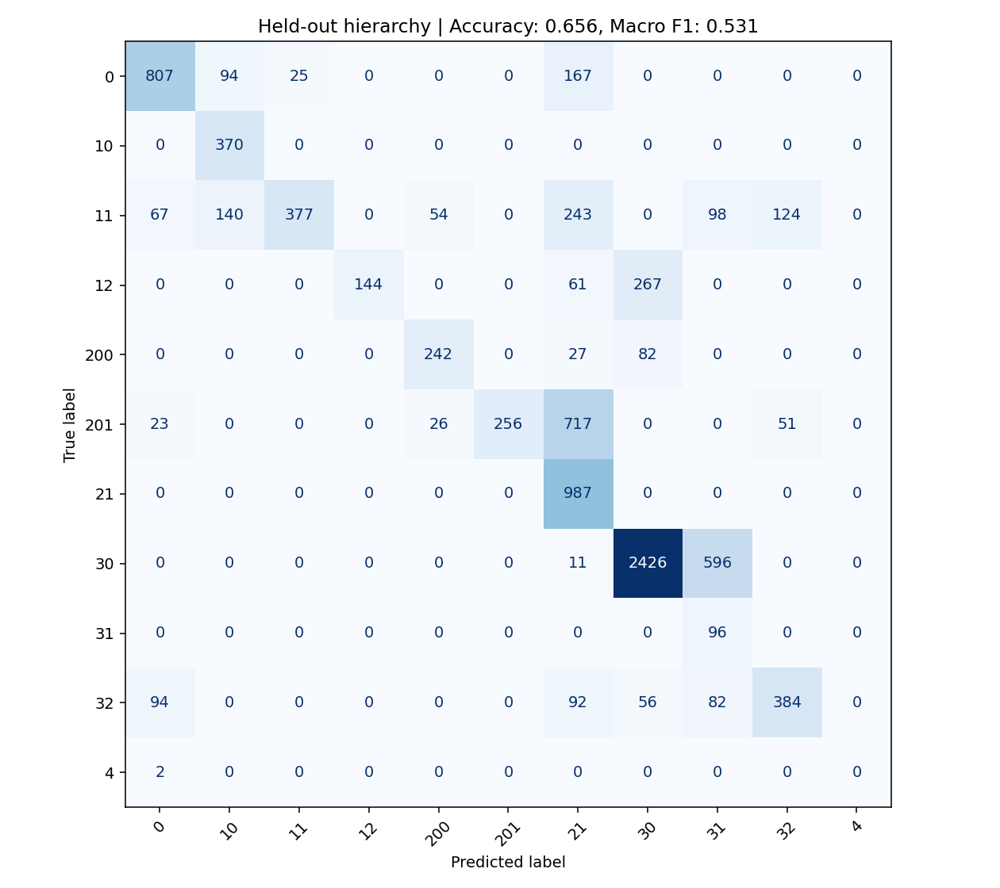

Held-out hierarchy accuracy: 0.6556 | Saved: /home/kmanabe2403/dune/training/output/full_archived_labels_001/models/hierarchy_evaluation


In [24]:
# Cell 24: Evaluate the complete hierarchy on held-out images after export.
# Use evaluation models only; reuse implementation's GMM-cluster majority routing.
from training_bundle import evaluate_hierarchy

evaluate_hierarchy(PROJECT_ROOT, RUN_DIR)